# 02. Класичне машинне навчання (SVM і Random Forest)

Перевіримо наскільки добре працюватимуть класичні моделі без нейронних мереж.

1. Завантаження даних і підготовка ознак (сирі пікселі та HOG).
2. SVM на сирих пікселях.
3. Підбір параметра `C` для SVM на HOG.
4. Random Forest на HOG.
5. Порівняння всіх моделей на val і test.

### 1) Імпорти, шляхи, seed

Підключаємо бібліотеки, шляхи до даних і результатів. `SEED = 42` фіксує випадковість, щоб результати відтворювались.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from skimage.feature import hog

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = Path("../data/chest_xray")
RESULTS_DIR = Path("../results")
SEED = 42

### 2) Завантаження розбиття

Мітку класу перетворюємо на число: `PNEUMONIA` = 1, `NORMAL` = 0. Виводимо кількість знімків у кожній частині.

In [ ]:
df = pd.read_csv(RESULTS_DIR / "splits.csv")
df["y"] = (df["label"] == "PNEUMONIA").astype(int)

print(df.groupby(["new_split", "label"]).size().unstack())

label      NORMAL  PNEUMONIA
new_split                   
test          234        390
train        1079       3081
val           270        802


У train і val пневмонії близько 74-75%, а в test 62,5%. Тобто test трохи збалансованіший, ніж дані, на яких вчимось.

### 3) Завантаження знімків

Кожен знімок відкриваємо, переводимо в чорно-білий і зменшуємо до 128 * 128. Результат зберігаємо в кеш `cache_128.npz`, тому наступні запуски ноутбука не читають 5 856 файлів заново, а беруть масив з кешу.

In [ ]:
IMG = 128
cache_file = DATA_DIR.parent / "cache_128.npz"

def load_image(r):
    img = Image.open(DATA_DIR / r.split / r.label / r.filename)
    img = img.convert("L").resize((IMG, IMG))
    return np.asarray(img, dtype=np.uint8)

if cache_file.exists():
    X_img = np.load(cache_file)["X"]
    print("Завантажено з кешу")
else:
    X_img = np.stack([load_image(r) for r in tqdm(df.itertuples(), total=len(df))])
    np.savez_compressed(cache_file, X=X_img)

print(X_img.shape)

100%|██████████| 5856/5856 [01:09<00:00, 83.76it/s] 


(5856, 128, 128)


Отримали масив (5 856, 128, 128): 5 856 знімків розміром 128 × 128. Перший запуск зайняв близько хвилини.

### 4) Ознаки: сирі пікселі та HOG

Нам потрібно отримати вектор чисел для кожного знімка, бо класичні моделі не працюють із зображенням як із картинкою. Робимо два варіанти:

- **Сирі пікселі**: зменшуємо знімок до 64 × 64 (усереднення блоків 2 × 2), нормуємо значення в діапазон 0-1 і розгортаємо в вектор з 4 096 чисел. Зменшуємо ще раз, щоб модель навчалась швидше.
- **HOG** (гістограма орієнтованих градієнтів): знімок ділиться на клітинки 16 × 16, і в кожній рахується, у яких напрямках змінюється яскравість. Так описуються контури й текстури (ребра, межі легень), а не окремі пікселі. Виходить вектор з 1 764 чисел.

In [ ]:
X_raw = X_img.reshape(-1, 64, 2, 64, 2).mean(axis=(2, 4)).reshape(len(df), -1) / 255.0

X_hog = np.stack([
    hog(im, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
    for im in tqdm(X_img)
])

print("raw:", X_raw.shape, "| hog:", X_hog.shape)

100%|██████████| 5856/5856 [00:08<00:00, 654.48it/s]

raw: (5856, 4096) | hog: (5856, 1764)


Отримали по одному вектору на знімок: 4 096 ознак для сирих пікселів і 1 764 для HOG.

### 5) Маски train/val/test

Створюємо булеві маски за стовпцем `new_split`, щоб вибирати потрібні рядки і з ознак, і з міток. Перевіряємо розміри: 4 160 / 1 072 / 624.

In [5]:
tr = (df["new_split"] == "train").values
va = (df["new_split"] == "val").values
te = (df["new_split"] == "test").values
y = df["y"].values

print("train:", tr.sum(), "| val:", va.sum(), "| test:", te.sum())

train: 4160 | val: 1072 | test: 624


### 6) Функції оцінювання

Описуємо дві допоміжні функції, щоб однаково оцінювати всі моделі:

- `evaluate` повертає accuracy, precision, recall, specificity і F1. Через дисбаланс класів одної accuracy замало: recall показує, скільки хворих знайдено, а specificity, скільки здорових названо здоровими.
- `show_cm` будує матрицю помилок і за потреби зберігає її в картинку.

In [ ]:
def evaluate(model, X, y_true, name, split):
    pred = model.predict(X)
    return {
        "model": name,
        "split": split,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred),
        "recall": recall_score(y_true, pred), 
        "specificity": recall_score(y_true, pred, pos_label=0),
        "f1": f1_score(y_true, pred),
    }

def show_cm(model, X, y_true, title, filename=None):
    pred = model.predict(X)
    cm = confusion_matrix(y_true, pred)
    ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "PNEUMONIA"]).plot(cmap="Blues", colorbar=False)
    plt.title(title)
    plt.tight_layout()
    if filename:
        plt.savefig(RESULTS_DIR / filename, dpi=150)
    plt.show()

### 7) SVM на сирих пікселях

Перша модель: метод опорних векторів з ядром RBF. Перед ним ставимо `StandardScaler`, тому що SVM чутливий до масштабу ознак. Масштабування і модель об'єднані в `pipeline`, тож середнє і розкид рахуються лише по train. `class_weight="balanced"` підсилює помилки на рідшому класі (NORMAL), щоб дисбаланс не змушував модель завжди визначати пневмонію. Навчаємо на train, оцінюємо на val.

In [7]:
svm_raw = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1, class_weight="balanced", random_state=SEED)
)
svm_raw.fit(X_raw[tr], y[tr])

res = evaluate(svm_raw, X_raw[va], y[va], "SVM (raw pixels)", "val")
print(pd.Series(res))

model          SVM (raw pixels)
split                       val
accuracy               0.969216
precision              0.983648
recall                 0.975062
specificity            0.951852
f1                     0.979336
dtype: object


На val SVM на сирих пікселях дає accuracy 0,969 і F1 0,979. Для простої моделі хороший результат, але val ми ще не вважаємо остаточною перевіркою.

### 8) Підбір параметра C для SVM на HOG

`C` керує суворістю моделі: малий `C` дає простішу межу рішення з більшою кількістю помилок на train, великий намагається підігнатись під train точніше. Пробуємо `C` = 0.1, 1, 10, навчаємо SVM на HOG для кожного значення і порівнюємо метрики на val. Test тут не використовуємо, щоб не підлаштовувати модель під нього.

In [8]:
tuning = []
for C in [0.1, 1, 10]:
    m = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=C, class_weight="balanced", random_state=SEED)
    )
    m.fit(X_hog[tr], y[tr])
    r = evaluate(m, X_hog[va], y[va], f"SVM HOG C={C}", "val")
    r["C"] = C
    tuning.append(r)

tuning_df = pd.DataFrame(tuning)
tuning_df[["C", "accuracy", "precision", "recall", "specificity", "f1"]]

,C,accuracy,precision,recall,specificity,f1
0,0.1,0.950560,0.985733,0.947631,0.959259,0.966306
1,1.0,0.974813,0.987421,0.978803,0.962963,0.983093
2,10.0,0.979478,0.983871,0.988778,0.951852,0.986318


Найкраще `C` = 10 (F1 0,986, recall 0,989). Різниця між `C` = 1 і `C` = 10 мала, а `C` = 0.1 явно гірше. Specificity на val майже не змінюється (0,95-0,96).

### 9) Останній SVM на HOG

Вибираємо `C` з найбільшим F1 на val і навчаємо SVM з цим значенням. `C` = 10.

In [9]:
best_C = tuning_df.sort_values("f1", ascending=False).iloc[0]["C"]
print("Найкраще C за F1 на val:", best_C)

svm_hog = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=best_C, class_weight="balanced", random_state=SEED)
)
svm_hog.fit(X_hog[tr], y[tr])

Найкраще C за F1 на val: 10.0


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc',
                 SVC(C=np.float64(10.0), class_weight='balanced',
                     random_state=42))])

### 10) Random Forest на HOG

Другий класичний підхід: ліс з 300 дерев рішень, кожне навчається на випадковій підвибірці знімків і ознак, а відповідь визначається голосуванням. `class_weight="balanced"` працює так само, як у SVM. Оцінюємо на val.

In [10]:
rf_hog = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED
)
rf_hog.fit(X_hog[tr], y[tr])

print(pd.Series(evaluate(rf_hog, X_hog[va], y[va], "Random Forest (HOG)", "val")))

model          Random Forest (HOG)
split                          val
accuracy                  0.960821
precision                 0.965686
recall                    0.982544
specificity               0.896296
f1                        0.974042
dtype: object


На val Random Forest трохи гірший за SVM: accuracy 0,961, а specificity 0,896.

### 11) Порівняння на val і test

Збираємо метрики всіх трьох моделей на val і на test в одну таблицю. 

In [11]:
models = {
    "SVM (raw pixels)": (svm_raw, X_raw),
    "SVM (HOG)": (svm_hog, X_hog),
    "Random Forest (HOG)": (rf_hog, X_hog),
}

all_res = []
for name, (model, X) in models.items():
    all_res.append(evaluate(model, X[va], y[va], name, "val"))
    all_res.append(evaluate(model, X[te], y[te], name, "test"))

metrics = pd.DataFrame(all_res)
metrics.to_csv(RESULTS_DIR / "metrics_classical.csv", index=False)

metrics.round(3)

,model,split,accuracy,precision,recall,specificity,f1
0,SVM (raw pixels),val,0.969,0.984,0.975,0.952,0.979
1,SVM (raw pixels),test,0.795,0.760,0.982,0.483,0.857
2,SVM (HOG),val,0.979,0.984,0.989,0.952,0.986
3,SVM (HOG),test,0.769,0.731,0.997,0.389,0.844
4,Random Forest (HOG),val,0.961,0.966,0.983,0.896,0.974
5,Random Forest (HOG),test,0.742,0.712,0.987,0.333,0.827


**Результат:** на val усі моделі добре працюють (accuracy 0,96-0,98), але на test набагато гірше: 0,74-0,80. Recall при цьому залишається високим (0,98-0,997), а specificity падає до 0,33-0,48. Тобто модель майже не пропускає хворих, але багато здорових називає хворими. Val-метрики для класичного ML завищені, справжню якість показує test.

### 12) Матриця помилок найкращої моделі

Будуємо матрицю помилок на test для SVM на HOG (найкраща за val F1). Видно, скільки здорових знімків модель помилково назвала пневмонією і скільки хворих пропустила.

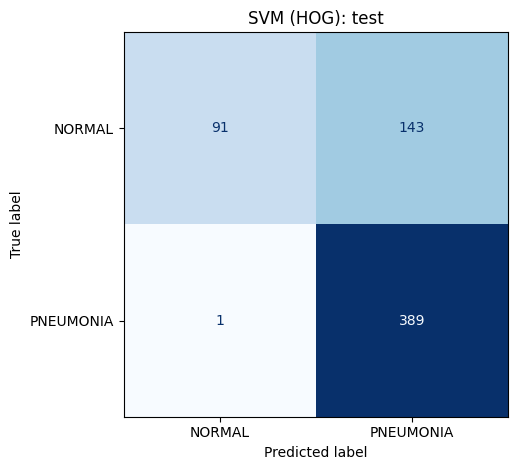

In [12]:
show_cm(svm_hog, X_hog[te], y[te], "SVM (HOG): test", "cm_svm_hog.png")

На test SVM на HOG пропускає лише 1 хворого, але хибно позначає пневмонією 143 здорових з 234 (specificity 0,389).

## Підсумок

**Що ми зробили**
- Підготували два набори ознак: сирі пікселі (4 096) і HOG (1 764).
- Навчили три моделі: SVM (сирі пікселі), SVM (HOG, `C` підібране на val) і Random Forest (HOG).
- Оцінили їх на val і test.

**Висновки**
- На val усі моделі показують accuracy 0,96-0,98, на test лише 0,74-0,80.
- Recall високий (понад 0,98), specificity низька (0,33-0,48): багато здорових знімків модель вважає хворими.
- Найкраща за val F1 модель, SVM на HOG, на test має accuracy 0,769. Це базовий рівень для порівняння з CNN і transfer learning.